In [1]:

def asal_carpanlari_bul(n):
    carpanlar = []
    bolen = 2

    while bolen * bolen <= n:
        while n % bolen == 0:
            carpanlar.append(bolen)
            n = n // bolen

        bolen += 1

    if n > 1:
        carpanlar.append(n)

    return carpanlar


print(asal_carpanlari_bul(24))
print(asal_carpanlari_bul(36))


[2, 2, 2, 3]
[2, 2, 3, 3]


In [2]:

def gcd1(a, b):
    carpanlar_a = asal_carpanlari_bul(a)
    carpanlar_b = asal_carpanlari_bul(b)

    ebob = 1

    for sayi in carpanlar_a:
        if sayi in carpanlar_b:
            ebob = ebob * sayi
            carpanlar_b.remove(sayi)

    return ebob

print("EBOB:", gcd1(24, 36))


EBOB: 12


In [3]:

import time

# İki sayımız
sayi1 = 144
sayi2 = 216

# Başlangıç zamanını kaydet
baslangic = time.perf_counter()

# GCD1 algoritmasını çalıştır
sonuc = gcd1(sayi1, sayi2)

# Bitiş zamanını kaydet
bitis = time.perf_counter()

# Saniyeyi milisaniyeye çevir
sure_ms = (bitis - baslangic) * 1000

print("Sayı 1:", sayi1)
print("Sayı 2:", sayi2)
print("EBOB:", sonuc)
print("GCD1 çalışma süresi:", sure_ms, "ms")


Sayı 1: 144
Sayı 2: 216
EBOB: 72
GCD1 çalışma süresi: 0.12230100000465427 ms


In [4]:

import random

for basamak in range(3, 11):
    alt_sinir = 10 ** (basamak - 1)
    ust_sinir = 10 ** basamak - 1

    sayi1 = random.randint(alt_sinir, ust_sinir)
    sayi2 = random.randint(alt_sinir, ust_sinir)

    print(f"{basamak} basamaklı sayılar: {sayi1}, {sayi2}")


3 basamaklı sayılar: 207, 391
4 basamaklı sayılar: 4875, 3413
5 basamaklı sayılar: 63030, 83636
6 basamaklı sayılar: 494373, 908440
7 basamaklı sayılar: 5209645, 5120526
8 basamaklı sayılar: 10497352, 75359756
9 basamaklı sayılar: 743418434, 433086551
10 basamaklı sayılar: 3699084419, 8465812375


In [5]:

import time

# Daha önce ürettiğimiz rastgele sayı çiftleri
sayilar = [
    (207, 391),
    (4875, 3413),
    (63030, 83636),
    (494373, 908440),
    (5209645, 5120526),
    (10497352, 75359756),
    (743418434, 433086551),
    (3699084419, 8465812375)
]

# Sonuçların saklanacağı liste
gcd1_sonuclari = []

for sayi1, sayi2 in sayilar:

    baslangic = time.perf_counter()

    ebob = gcd1(sayi1, sayi2)

    bitis = time.perf_counter()

    sure_ms = (bitis - baslangic) * 1000

    gcd1_sonuclari.append(
        (sayi1, sayi2, ebob, sure_ms)
    )

    print(
        f"Sayı 1: {sayi1}, "
        f"Sayı 2: {sayi2}, "
        f"EBOB: {ebob}, "
        f"GCD1 Süresi: {sure_ms:.6f} ms"
    )


Sayı 1: 207, Sayı 2: 391, EBOB: 23, GCD1 Süresi: 0.009357 ms
Sayı 1: 4875, Sayı 2: 3413, EBOB: 1, GCD1 Süresi: 0.014324 ms
Sayı 1: 63030, Sayı 2: 83636, EBOB: 2, GCD1 Süresi: 0.010499 ms
Sayı 1: 494373, Sayı 2: 908440, EBOB: 1, GCD1 Süresi: 0.014574 ms
Sayı 1: 5209645, Sayı 2: 5120526, EBOB: 1, GCD1 Süresi: 0.019169 ms
Sayı 1: 10497352, Sayı 2: 75359756, EBOB: 4, GCD1 Süresi: 0.199596 ms
Sayı 1: 743418434, Sayı 2: 433086551, EBOB: 19, GCD1 Süresi: 0.147068 ms
Sayı 1: 3699084419, Sayı 2: 8465812375, EBOB: 1, GCD1 Süresi: 11.088218 ms


In [6]:

import time
import statistics

gcd1_sureleri = []
gcd1_eboblar = []

for sayi1, sayi2 in sayilar:
    olcumler = []

    for tekrar in range(30):
        baslangic = time.perf_counter_ns()

        ebob = gcd1(sayi1, sayi2)

        bitis = time.perf_counter_ns()

        sure_ms = (bitis - baslangic) / 1_000_000
        olcumler.append(sure_ms)

    medyan_sure = statistics.median(olcumler)

    gcd1_sureleri.append(medyan_sure)
    gcd1_eboblar.append(ebob)

    basamak = len(str(sayi1))

    print(
        f"{basamak} basamak | "
        f"EBOB: {ebob} | "
        f"Medyan süre: {medyan_sure:.6f} ms"
    )


3 basamak | EBOB: 23 | Medyan süre: 0.005606 ms
4 basamak | EBOB: 1 | Medyan süre: 0.012560 ms
5 basamak | EBOB: 2 | Medyan süre: 0.009883 ms
6 basamak | EBOB: 1 | Medyan süre: 0.022101 ms
7 basamak | EBOB: 1 | Medyan süre: 0.030526 ms
8 basamak | EBOB: 4 | Medyan süre: 0.391628 ms
9 basamak | EBOB: 19 | Medyan süre: 0.271952 ms
10 basamak | EBOB: 1 | Medyan süre: 19.450184 ms


In [7]:

def gcd2(a, b):
    t = min(a, b)

    while t > 0:
        if a % t == 0 and b % t == 0:
            return t

        t = t - 1

print("EBOB:", gcd2(24, 36))


EBOB: 12


In [8]:

import time
import statistics

# Önceden kaydettiğimiz ilk üç sayı çifti
kucuk_sayilar = sayilar[:3]

gcd2_sonuclari = []

for sayi1, sayi2 in kucuk_sayilar:
    olcumler = []

    for tekrar in range(30):
        baslangic = time.perf_counter_ns()

        ebob = gcd2(sayi1, sayi2)

        bitis = time.perf_counter_ns()

        sure_ms = (bitis - baslangic) / 1_000_000
        olcumler.append(sure_ms)

    medyan_sure = statistics.median(olcumler)
    gcd2_sonuclari.append((sayi1, sayi2, ebob, medyan_sure))

    print(
        f"{len(str(sayi1))} basamak | "
        f"EBOB: {ebob} | "
        f"GCD2 medyan süre: {medyan_sure:.6f} ms"
    )


3 basamak | EBOB: 23 | GCD2 medyan süre: 0.013730 ms
4 basamak | EBOB: 1 | GCD2 medyan süre: 0.314380 ms
5 basamak | EBOB: 2 | GCD2 medyan süre: 5.938756 ms


In [9]:

# 6 basamaklı deney sayılarımız
sayi1 = 494373
sayi2 = 908440

# GCD1 ile EBOB değerini bul
ebob = gcd1(sayi1, sayi2)

# GCD2'nin kontrol edeceği aday sayısı
kontrol_sayisi = min(sayi1, sayi2) - ebob + 1

print("Sayı 1:", sayi1)
print("Sayı 2:", sayi2)
print("EBOB:", ebob)
print("GCD2 kontrol sayısı:", kontrol_sayisi)


Sayı 1: 494373
Sayı 2: 908440
EBOB: 1
GCD2 kontrol sayısı: 494373


In [10]:

import time

sayi1 = 494373
sayi2 = 908440

baslangic = time.perf_counter()

sonuc = gcd2(sayi1, sayi2)

bitis = time.perf_counter()

sure_ms = (bitis - baslangic) * 1000

print("Sayı 1:", sayi1)
print("Sayı 2:", sayi2)
print("EBOB:", sonuc)
print(f"GCD2 çalışma süresi: {sure_ms:.6f} ms")


Sayı 1: 494373
Sayı 2: 908440
EBOB: 1
GCD2 çalışma süresi: 56.481682 ms


In [11]:

print("GCD2 - Kalan deneylerin kontrol sayıları")

for sayi1, sayi2 in sayilar[4:]:
    basamak = len(str(sayi1))
    ebob = gcd1(sayi1, sayi2)

    kontrol_sayisi = min(sayi1, sayi2) - ebob + 1

    print(
        f"{basamak} basamak | "
        f"EBOB: {ebob} | "
        f"Kontrol sayısı: {kontrol_sayisi:,}"
    )


GCD2 - Kalan deneylerin kontrol sayıları
7 basamak | EBOB: 1 | Kontrol sayısı: 5,120,526
8 basamak | EBOB: 4 | Kontrol sayısı: 10,497,349
9 basamak | EBOB: 19 | Kontrol sayısı: 433,086,533
10 basamak | EBOB: 1 | Kontrol sayısı: 3,699,084,419


In [12]:

import time

# 7 ve 8 basamaklı sayılar
for sayi1, sayi2 in sayilar[4:6]:

    basamak = len(str(sayi1))

    baslangic = time.perf_counter()

    ebob = gcd2(sayi1, sayi2)

    bitis = time.perf_counter()

    sure_ms = (bitis - baslangic) * 1000

    print(
        f"{basamak} basamak | "
        f"EBOB: {ebob} | "
        f"GCD2 süresi: {sure_ms:.6f} ms"
    )


7 basamak | EBOB: 1 | GCD2 süresi: 489.934474 ms
8 basamak | EBOB: 4 | GCD2 süresi: 1026.360663 ms


In [13]:

def gcd3(a, b):
    ebob = 1

    for t in range(1, min(a, b) + 1):
        if a % t == 0 and b % t == 0:
            ebob = t

    return ebob


print("EBOB:", gcd3(24, 36))


EBOB: 12


In [14]:

import time
import statistics

gcd3_sonuclari = []

# İlk üç sayı çiftini kullanıyoruz
for sayi1, sayi2 in sayilar[:3]:
    olcumler = []

    for tekrar in range(30):
        baslangic = time.perf_counter_ns()

        ebob = gcd3(sayi1, sayi2)

        bitis = time.perf_counter_ns()

        sure_ms = (bitis - baslangic) / 1_000_000
        olcumler.append(sure_ms)

    medyan_sure = statistics.median(olcumler)

    gcd3_sonuclari.append(
        (sayi1, sayi2, ebob, medyan_sure)
    )

    print(
        f"{len(str(sayi1))} basamak | "
        f"EBOB: {ebob} | "
        f"GCD3 medyan süre: {medyan_sure:.6f} ms"
    )


3 basamak | EBOB: 23 | GCD3 medyan süre: 0.010471 ms
4 basamak | EBOB: 1 | GCD3 medyan süre: 0.335425 ms
5 basamak | EBOB: 2 | GCD3 medyan süre: 4.343720 ms


In [15]:

import time

# 6, 7 ve 8 basamaklı sayılar
for sayi1, sayi2 in sayilar[3:6]:

    basamak = len(str(sayi1))

    baslangic = time.perf_counter()

    ebob = gcd3(sayi1, sayi2)

    bitis = time.perf_counter()

    sure_ms = (bitis - baslangic) * 1000

    print(
        f"{basamak} basamak | "
        f"EBOB: {ebob} | "
        f"GCD3 süresi: {sure_ms:.6f} ms"
    )


6 basamak | EBOB: 1 | GCD3 süresi: 37.289647 ms
7 basamak | EBOB: 1 | GCD3 süresi: 391.609755 ms
8 basamak | EBOB: 4 | GCD3 süresi: 728.887045 ms


In [16]:

def gcd4(a, b):
    while a != b:
        if a > b:
            a = a - b
        else:
            b = b - a

    return a


print("EBOB:", gcd4(24, 36))


EBOB: 12


In [17]:

import time
import statistics

gcd4_sonuclari = []

for sayi1, sayi2 in sayilar:
    olcumler = []

    for tekrar in range(30):
        baslangic = time.perf_counter_ns()

        ebob = gcd4(sayi1, sayi2)

        bitis = time.perf_counter_ns()

        sure_ms = (bitis - baslangic) / 1_000_000
        olcumler.append(sure_ms)

    medyan_sure = statistics.median(olcumler)

    gcd4_sonuclari.append(
        (sayi1, sayi2, ebob, medyan_sure)
    )

    print(
        f"{len(str(sayi1))} basamak | "
        f"EBOB: {ebob} | "
        f"GCD4 medyan süre: {medyan_sure:.6f} ms"
    )


3 basamak | EBOB: 23 | GCD4 medyan süre: 0.000817 ms
4 basamak | EBOB: 1 | GCD4 medyan süre: 0.006814 ms
5 basamak | EBOB: 2 | GCD4 medyan süre: 0.041303 ms
6 basamak | EBOB: 1 | GCD4 medyan süre: 0.002952 ms
7 basamak | EBOB: 1 | GCD4 medyan süre: 0.007220 ms
8 basamak | EBOB: 4 | GCD4 medyan süre: 0.005512 ms
9 basamak | EBOB: 19 | GCD4 medyan süre: 0.004303 ms
10 basamak | EBOB: 1 | GCD4 medyan süre: 0.007239 ms


In [18]:

def gcd5(a, b):
    while b != 0:
        kalan = a % b
        a = b
        b = kalan

    return a


print("EBOB:", gcd5(24, 36))


EBOB: 12


In [19]:

import time
import statistics

gcd5_sonuclari = []

for sayi1, sayi2 in sayilar:
    olcumler = []

    for tekrar in range(30):
        baslangic = time.perf_counter_ns()

        ebob = gcd5(sayi1, sayi2)

        bitis = time.perf_counter_ns()

        sure_ms = (bitis - baslangic) / 1_000_000
        olcumler.append(sure_ms)

    medyan_sure = statistics.median(olcumler)

    gcd5_sonuclari.append(
        (sayi1, sayi2, ebob, medyan_sure)
    )

    print(
        f"{len(str(sayi1))} basamak | "
        f"EBOB: {ebob} | "
        f"GCD5 medyan süre: {medyan_sure:.6f} ms"
    )


3 basamak | EBOB: 23 | GCD5 medyan süre: 0.000472 ms
4 basamak | EBOB: 1 | GCD5 medyan süre: 0.000707 ms
5 basamak | EBOB: 2 | GCD5 medyan süre: 0.000599 ms
6 basamak | EBOB: 1 | GCD5 medyan süre: 0.001164 ms
7 basamak | EBOB: 1 | GCD5 medyan süre: 0.001046 ms
8 basamak | EBOB: 4 | GCD5 medyan süre: 0.001115 ms
9 basamak | EBOB: 19 | GCD5 medyan süre: 0.001311 ms
10 basamak | EBOB: 1 | GCD5 medyan süre: 0.001945 ms


In [20]:

# GCD algoritmalarının doğruluğunu kontrol etme

for sayi1, sayi2 in sayilar:
    sonuc1 = gcd1(sayi1, sayi2)
    sonuc4 = gcd4(sayi1, sayi2)
    sonuc5 = gcd5(sayi1, sayi2)

    assert sonuc1 == sonuc4 == sonuc5

    print(
        f"{len(str(sayi1))} basamak: "
        f"EBOB = {sonuc5} - DOĞRU"
    )

print("Tüm kontrol edilen sonuçlar eşleşti!")


3 basamak: EBOB = 23 - DOĞRU
4 basamak: EBOB = 1 - DOĞRU
5 basamak: EBOB = 2 - DOĞRU
6 basamak: EBOB = 1 - DOĞRU
7 basamak: EBOB = 1 - DOĞRU
8 basamak: EBOB = 4 - DOĞRU
9 basamak: EBOB = 19 - DOĞRU
10 basamak: EBOB = 1 - DOĞRU
Tüm kontrol edilen sonuçlar eşleşti!


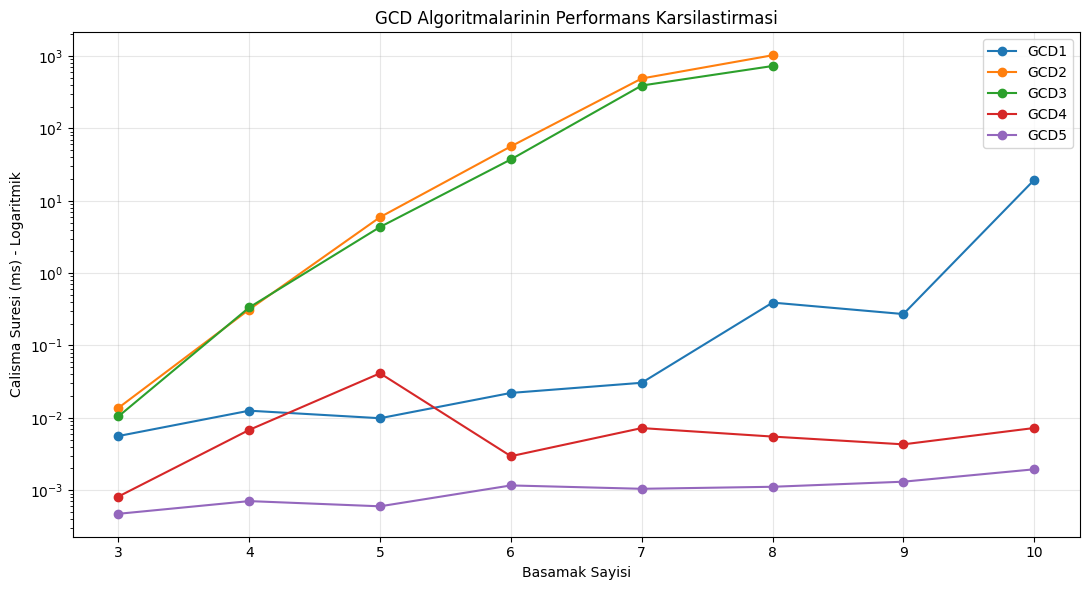

In [21]:

import matplotlib.pyplot as plt
import numpy as np

basamaklar = [3, 4, 5, 6, 7, 8, 9, 10]

gcd1_ms = [0.005606, 0.012560, 0.009883, 0.022101,
           0.030526, 0.391628, 0.271952, 19.450184]

gcd2_ms = [0.013730, 0.314380, 5.938756, 56.481682,
           489.934474, 1026.360663, np.nan, np.nan]

gcd3_ms = [0.010471, 0.335425, 4.343720, 37.289647,
           391.609755, 728.887045, np.nan, np.nan]

gcd4_ms = [0.000817, 0.006814, 0.041303, 0.002952,
           0.007220, 0.005512, 0.004303, 0.007239]

gcd5_ms = [0.000472, 0.000707, 0.000599, 0.001164,
           0.001046, 0.001115, 0.001311, 0.001945]

plt.figure(figsize=(11, 6))

plt.plot(basamaklar, gcd1_ms, marker='o', label='GCD1')
plt.plot(basamaklar, gcd2_ms, marker='o', label='GCD2')
plt.plot(basamaklar, gcd3_ms, marker='o', label='GCD3')
plt.plot(basamaklar, gcd4_ms, marker='o', label='GCD4')
plt.plot(basamaklar, gcd5_ms, marker='o', label='GCD5')

plt.yscale('log')

plt.xlabel('Basamak Sayisi')
plt.ylabel('Calisma Suresi (ms) - Logaritmik')
plt.title('GCD Algoritmalarinin Performans Karsilastirmasi')

plt.xticks(basamaklar)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:

import time
import statistics

algoritmalar = {
    "GCD1": gcd1,
    "GCD4": gcd4,
    "GCD5": gcd5
}

for basamak, (a, b) in enumerate(sayilar, start=3):
    print(f"\n{basamak} basamak:")

    for isim, fonksiyon in algoritmalar.items():
        olcumler = []

        for _ in range(30):
            baslangic = time.perf_counter_ns()
            sonuc = fonksiyon(a, b)
            bitis = time.perf_counter_ns()

            olcumler.append(
                (bitis - baslangic) / 1_000_000
            )

        medyan = statistics.median(olcumler)

        assert sonuc == gcd5(a, b)

        print(f"{isim}: {medyan:.6f} ms")



3 basamak:
GCD1: 0.005640 ms
GCD4: 0.001339 ms
GCD5: 0.000971 ms

4 basamak:
GCD1: 0.012852 ms
GCD4: 0.011419 ms
GCD5: 0.001375 ms

5 basamak:
GCD1: 0.009966 ms
GCD4: 0.070870 ms
GCD5: 0.001171 ms

6 basamak:
GCD1: 0.022234 ms
GCD4: 0.005130 ms
GCD5: 0.002218 ms

7 basamak:
GCD1: 0.030589 ms
GCD4: 0.012901 ms
GCD5: 0.001991 ms

8 basamak:
GCD1: 0.375379 ms
GCD4: 0.009316 ms
GCD5: 0.002228 ms

9 basamak:
GCD1: 0.274742 ms
GCD4: 0.007606 ms
GCD5: 0.002490 ms

10 basamak:
GCD1: 77.189855 ms
GCD4: 0.012819 ms
GCD5: 0.003768 ms


In [23]:

import time
import statistics

for isim, fonksiyon in [("GCD2", gcd2), ("GCD3", gcd3)]:

    print(f"\n{isim} SONUÇLARI")

    for sayi1, sayi2 in sayilar[3:6]:
        olcumler = []

        for _ in range(5):
            baslangic = time.perf_counter_ns()

            sonuc = fonksiyon(sayi1, sayi2)

            bitis = time.perf_counter_ns()

            olcumler.append(
                (bitis - baslangic) / 1_000_000
            )

        medyan = statistics.median(olcumler)

        print(
            f"{len(str(sayi1))} basamak | "
            f"EBOB: {sonuc} | "
            f"Medyan: {medyan:.6f} ms"
        )



GCD2 SONUÇLARI
6 basamak | EBOB: 1 | Medyan: 48.438952 ms
7 basamak | EBOB: 1 | Medyan: 509.684365 ms
8 basamak | EBOB: 4 | Medyan: 1369.199812 ms

GCD3 SONUÇLARI
6 basamak | EBOB: 1 | Medyan: 34.271798 ms
7 basamak | EBOB: 1 | Medyan: 379.663401 ms
8 basamak | EBOB: 4 | Medyan: 755.542466 ms


In [24]:

import pandas as pd

veriler = {
    "Basamak": [3, 4, 5, 6, 7, 8, 9, 10],
    "GCD1_ms": [0.005640, 0.012852, 0.009966, 0.022234,
                0.030589, 0.375379, 0.274742, 77.189855],
    "GCD2_ms": [0.013730, 0.314380, 5.938756, 48.438952,
                509.684365, 1369.199812, None, None],
    "GCD3_ms": [0.010471, 0.335425, 4.343720, 34.271798,
                379.663401, 755.542466, None, None],
    "GCD4_ms": [0.001339, 0.011419, 0.070870, 0.005130,
                0.012901, 0.009316, 0.007606, 0.012819],
    "GCD5_ms": [0.000971, 0.001375, 0.001171, 0.002218,
                0.001991, 0.002228, 0.002490, 0.003768]
}

df = pd.DataFrame(veriler)

df.to_csv("GCD_Deney_Sonuclari.csv", index=False)

print(df)
print("CSV dosyası kaydedildi.")


   Basamak    GCD1_ms      GCD2_ms     GCD3_ms   GCD4_ms   GCD5_ms
0        3   0.005640     0.013730    0.010471  0.001339  0.000971
1        4   0.012852     0.314380    0.335425  0.011419  0.001375
2        5   0.009966     5.938756    4.343720  0.070870  0.001171
3        6   0.022234    48.438952   34.271798  0.005130  0.002218
4        7   0.030589   509.684365  379.663401  0.012901  0.001991
5        8   0.375379  1369.199812  755.542466  0.009316  0.002228
6        9   0.274742          NaN         NaN  0.007606  0.002490
7       10  77.189855          NaN         NaN  0.012819  0.003768
CSV dosyası kaydedildi.


In [25]:

import time
import signal

# 9 basamaklı sayılarımız
sayi1 = 743418434
sayi2 = 433086551

# Colab'ın Linux ortamında zaman sınırı
class ZamanAsimi(Exception):
    pass

def alarm_handler(signum, frame):
    raise ZamanAsimi()

signal.signal(signal.SIGALRM, alarm_handler)

# Sonuçları saklayacağımız sözlük
gcd_9_sonuclari = {}

for isim, fonksiyon in [("GCD2", gcd2), ("GCD3", gcd3)]:

    print(f"{isim} başlıyor...", flush=True)

    baslangic = time.perf_counter()

    try:
        signal.alarm(120)

        sonuc = fonksiyon(sayi1, sayi2)

        bitis = time.perf_counter()
        sure_ms = (bitis - baslangic) * 1000

        gcd_9_sonuclari[isim] = sure_ms

        print("EBOB:", sonuc)
        print(f"{isim} süresi: {sure_ms:.6f} ms")

        assert sonuc == gcd5(sayi1, sayi2)

    except ZamanAsimi:
        gcd_9_sonuclari[isim] = None
        print(f"{isim}: 120 saniye sınırı aşıldı.")

    finally:
        signal.alarm(0)

    print("----------------------")


GCD2 başlıyor...
EBOB: 19
GCD2 süresi: 51346.653983 ms
----------------------
GCD3 başlıyor...
EBOB: 19
GCD3 süresi: 35455.775093 ms
----------------------


In [26]:

import time
import signal

sayi1 = 3699084419
sayi2 = 8465812375

class ZamanAsimi(Exception):
    pass

def alarm_handler(signum, frame):
    raise ZamanAsimi()

signal.signal(signal.SIGALRM, alarm_handler)

gcd_10_sonuclari = {}

for isim, fonksiyon in [("GCD2", gcd2), ("GCD3", gcd3)]:

    print(f"{isim} başlıyor...", flush=True)
    baslangic = time.perf_counter()

    try:
        signal.alarm(120)

        sonuc = fonksiyon(sayi1, sayi2)

        bitis = time.perf_counter()
        sure_ms = (bitis - baslangic) * 1000

        gcd_10_sonuclari[isim] = sure_ms

        print("EBOB:", sonuc)
        print(f"{isim} süresi: {sure_ms:.6f} ms")

        assert sonuc == gcd5(sayi1, sayi2)

    except ZamanAsimi:
        gcd_10_sonuclari[isim] = None
        print(f"{isim}: 120 saniyelik sınır aşıldı.")

    finally:
        signal.alarm(0)

    print("----------------------")


GCD2 başlıyor...
GCD2: 120 saniyelik sınır aşıldı.
----------------------
GCD3 başlıyor...
GCD3: 120 saniyelik sınır aşıldı.
----------------------


In [27]:

import time
import signal

# 10 basamaklı sayılarımız
sayi1 = 3699084419
sayi2 = 8465812375

# Yeni süre sınırı: 600 saniye
SURE_SINIRI = 600

class ZamanAsimi(Exception):
    pass

def alarm_handler(signum, frame):
    raise ZamanAsimi()

signal.signal(signal.SIGALRM, alarm_handler)

gcd_10_sonuclari = {}

for isim, fonksiyon in [("GCD2", gcd2), ("GCD3", gcd3)]:

    print(f"{isim} başlıyor...", flush=True)

    baslangic = time.perf_counter()

    try:
        signal.alarm(SURE_SINIRI)

        sonuc = fonksiyon(sayi1, sayi2)

        bitis = time.perf_counter()
        sure_ms = (bitis - baslangic) * 1000

        gcd_10_sonuclari[isim] = sure_ms

        print("EBOB:", sonuc)
        print(f"{isim} süresi: {sure_ms:.6f} ms")

        assert sonuc == gcd5(sayi1, sayi2)

    except ZamanAsimi:
        gcd_10_sonuclari[isim] = None
        print(f"{isim}: 600 saniyelik sınır aşıldı.")

    finally:
        signal.alarm(0)

    print("----------------------")


GCD2 başlıyor...
GCD2: 600 saniyelik sınır aşıldı.
----------------------
GCD3 başlıyor...


KeyboardInterrupt: 

In [28]:

import time
import signal

# Önceki deneyden kalan alarmı iptal et
signal.alarm(0)

# 10 basamaklı sayılarımız
sayi1 = 3699084419
sayi2 = 8465812375

# Sonuçları saklayacağımız sözlük
gcd_10_sonuclari = {}

# GCD2 ve GCD3 algoritmalarını test et
for isim, fonksiyon in [("GCD2", gcd2), ("GCD3", gcd3)]:

    print(f"{isim} başlıyor...", flush=True)

    baslangic = time.perf_counter()

    # Algoritmayı süre sınırı olmadan çalıştır
    sonuc = fonksiyon(sayi1, sayi2)

    bitis = time.perf_counter()

    # Süreyi milisaniyeye çevir
    sure_ms = (bitis - baslangic) * 1000

    gcd_10_sonuclari[isim] = sure_ms

    print("EBOB:", sonuc)
    print(f"{isim} süresi: {sure_ms:.6f} ms")
    print("----------------------")

    # Sonucu doğrula
    assert sonuc == gcd5(sayi1, sayi2)

print("Deneyler tamamlandı!")


GCD2 başlıyor...
EBOB: 1
GCD2 süresi: 747374.073671 ms
----------------------
GCD3 başlıyor...
EBOB: 1
GCD3 süresi: 597591.179073 ms
----------------------
Deneyler tamamlandı!


In [29]:

# Eksik GCD2 ve GCD3 sürelerini ekle
df.loc[df["Basamak"] == 9, "GCD2_ms"] = 51346.653983
df.loc[df["Basamak"] == 9, "GCD3_ms"] = 35455.775093

df.loc[df["Basamak"] == 10, "GCD2_ms"] = 747374.073671
df.loc[df["Basamak"] == 10, "GCD3_ms"] = 597591.179073

# Güncellenmiş dosyayı kaydet
df.to_csv("GCD_Deney_Sonuclari.csv", index=False)

print(df.to_string(index=False))
print("\nGüncel sonuçlar CSV dosyasına kaydedildi.")


 Basamak   GCD1_ms       GCD2_ms       GCD3_ms  GCD4_ms  GCD5_ms
       3  0.005640      0.013730      0.010471 0.001339 0.000971
       4  0.012852      0.314380      0.335425 0.011419 0.001375
       5  0.009966      5.938756      4.343720 0.070870 0.001171
       6  0.022234     48.438952     34.271798 0.005130 0.002218
       7  0.030589    509.684365    379.663401 0.012901 0.001991
       8  0.375379   1369.199812    755.542466 0.009316 0.002228
       9  0.274742  51346.653983  35455.775093 0.007606 0.002490
      10 77.189855 747374.073671 597591.179073 0.012819 0.003768

Güncel sonuçlar CSV dosyasına kaydedildi.


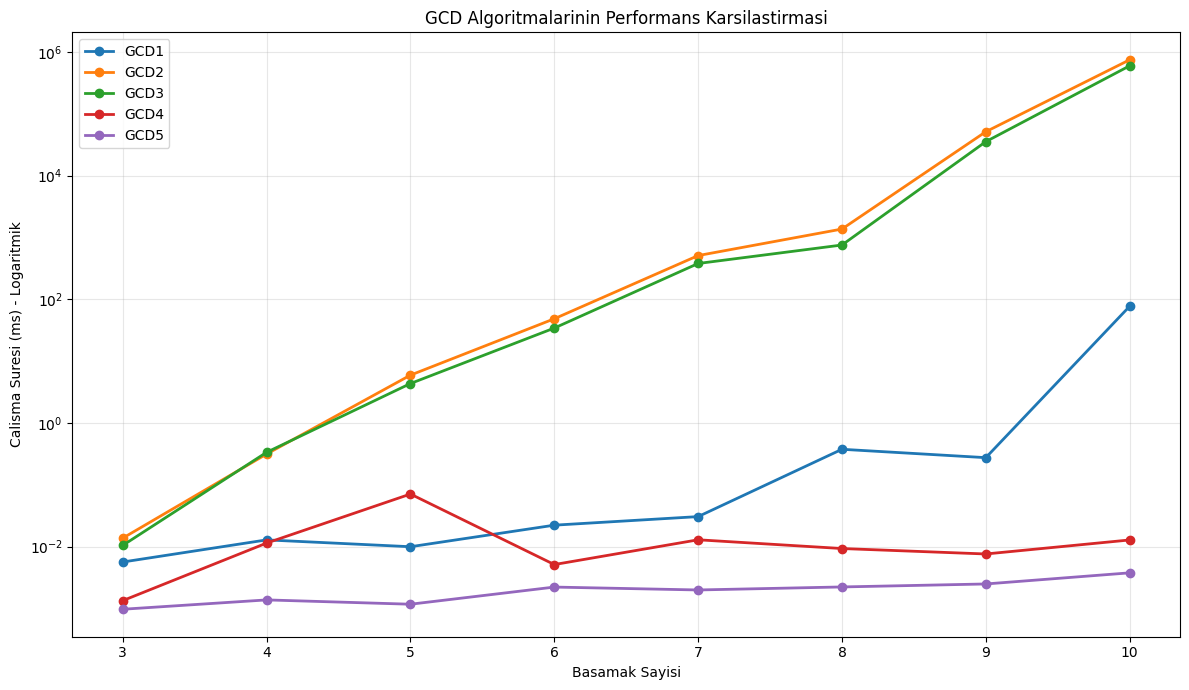

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# CSV tablosundaki güncel sonuçları kullan
for algoritma in ["GCD1", "GCD2", "GCD3", "GCD4", "GCD5"]:
    plt.plot(
        df["Basamak"],
        df[f"{algoritma}_ms"],
        marker="o",
        linewidth=2,
        label=algoritma
    )

# Çok farklı süreleri göstermek için
plt.yscale("log")

plt.xlabel("Basamak Sayisi")
plt.ylabel("Calisma Suresi (ms) - Logaritmik")
plt.title("GCD Algoritmalarinin Performans Karsilastirmasi")

plt.xticks(range(3, 11))
plt.grid(True, which="both", alpha=0.3)
plt.legend()

plt.tight_layout()

# Grafiği rapor için kaydet
plt.savefig(
    "GCD_Nihai_Performans_Grafigi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [31]:

def selection_sort(dizi):
    dizi = dizi.copy()
    karsilastirma = 0

    n = len(dizi)

    for i in range(n - 1):
        min_index = i

        for j in range(i + 1, n):
            karsilastirma += 1

            if dizi[j] < dizi[min_index]:
                min_index = j

        dizi[i], dizi[min_index] = dizi[min_index], dizi[i]

    return dizi, karsilastirma


ornek = [29, 10, 14, 37, 13]

sirali, adet = selection_sort(ornek)

print("Orijinal dizi:", ornek)
print("Sıralanmış dizi:", sirali)
print("Karşılaştırma sayısı:", adet)


Orijinal dizi: [29, 10, 14, 37, 13]
Sıralanmış dizi: [10, 13, 14, 29, 37]
Karşılaştırma sayısı: 10


In [32]:

import random

# Deneylerde kullanılacak dizi boyutları
dizi_boyutlari = [
    1000, 2000, 3000, 4000, 5000,
    6000, 7000, 8000, 9000, 10000
]

# Tekrarlanabilir deneyler için
random.seed(42)

# Rastgele dizileri oluştur
diziler = {}

for boyut in dizi_boyutlari:
    diziler[boyut] = [
        random.randint(1, 100000)
        for _ in range(boyut)
    ]

    print(
        f"{boyut} elemanlı dizi oluşturuldu. "
        f"İlk 5 eleman: {diziler[boyut][:5]}"
    )


1000 elemanlı dizi oluşturuldu. İlk 5 eleman: [83811, 14593, 3279, 97197, 36049]
2000 elemanlı dizi oluşturuldu. İlk 5 eleman: [57734, 44658, 24165, 6735, 33093]
3000 elemanlı dizi oluşturuldu. İlk 5 eleman: [23393, 70420, 51519, 69317, 16692]
4000 elemanlı dizi oluşturuldu. İlk 5 eleman: [74733, 22787, 49370, 85679, 49614]
5000 elemanlı dizi oluşturuldu. İlk 5 eleman: [78655, 28255, 37090, 95252, 88761]
6000 elemanlı dizi oluşturuldu. İlk 5 eleman: [16507, 52815, 87829, 781, 60662]
7000 elemanlı dizi oluşturuldu. İlk 5 eleman: [59631, 22957, 93089, 14402, 93511]
8000 elemanlı dizi oluşturuldu. İlk 5 eleman: [78092, 57062, 94926, 16948, 28536]
9000 elemanlı dizi oluşturuldu. İlk 5 eleman: [62225, 14200, 49310, 47811, 93032]
10000 elemanlı dizi oluşturuldu. İlk 5 eleman: [48248, 16014, 16403, 44906, 92811]


In [33]:

import time

selection_sonuclari = []

for boyut in dizi_boyutlari:

    # Daha önce oluşturduğumuz diziyi al
    dizi = diziler[boyut]

    # Başlangıç zamanını kaydet
    baslangic = time.perf_counter()

    # Selection Sort algoritmasını çalıştır
    sirali, karsilastirma = selection_sort(dizi)

    # Bitiş zamanını kaydet
    bitis = time.perf_counter()

    # Çalışma süresini milisaniyeye çevir
    sure_ms = (bitis - baslangic) * 1000

    # Sonucun doğru olduğunu kontrol et
    assert sirali == sorted(dizi)

    # Sonuçları kaydet
    selection_sonuclari.append(
        (boyut, sure_ms, karsilastirma)
    )

    print(
        f"{boyut} eleman | "
        f"Süre: {sure_ms:.4f} ms | "
        f"Karşılaştırma: {karsilastirma}"
    )


1000 eleman | Süre: 47.9796 ms | Karşılaştırma: 499500
2000 eleman | Süre: 173.1483 ms | Karşılaştırma: 1999000
3000 eleman | Süre: 410.5702 ms | Karşılaştırma: 4498500
4000 eleman | Süre: 707.7306 ms | Karşılaştırma: 7998000
5000 eleman | Süre: 1082.9903 ms | Karşılaştırma: 12497500
6000 eleman | Süre: 1658.1949 ms | Karşılaştırma: 17997000
7000 eleman | Süre: 3793.5111 ms | Karşılaştırma: 24496500
8000 eleman | Süre: 2774.8884 ms | Karşılaştırma: 31996000
9000 eleman | Süre: 3611.3952 ms | Karşılaştırma: 40495500
10000 eleman | Süre: 5195.2496 ms | Karşılaştırma: 49995000


In [34]:

def bubble_sort(dizi):
    dizi = dizi.copy()
    karsilastirma = 0

    n = len(dizi)

    for i in range(n - 1):
        for j in range(n - i - 1):
            karsilastirma += 1

            if dizi[j] > dizi[j + 1]:
                dizi[j], dizi[j + 1] = dizi[j + 1], dizi[j]

    return dizi, karsilastirma


ornek = [5, 3, 8, 1]

sirali, adet = bubble_sort(ornek)

print("Orijinal dizi:", ornek)
print("Sıralanmış dizi:", sirali)
print("Karşılaştırma sayısı:", adet)


Orijinal dizi: [5, 3, 8, 1]
Sıralanmış dizi: [1, 3, 5, 8]
Karşılaştırma sayısı: 6


In [35]:

import time

bubble_sonuclari = []

for boyut in dizi_boyutlari:

    # Selection Sort ile aynı diziyi kullan
    dizi = diziler[boyut]

    # Başlangıç zamanı
    baslangic = time.perf_counter()

    # Bubble Sort algoritmasını çalıştır
    sirali, karsilastirma = bubble_sort(dizi)

    # Bitiş zamanı
    bitis = time.perf_counter()

    # Milisaniyeye çevir
    sure_ms = (bitis - baslangic) * 1000

    # Doğruluğu kontrol et
    assert sirali == sorted(dizi)

    # Sonuçları kaydet
    bubble_sonuclari.append(
        (boyut, sure_ms, karsilastirma)
    )

    print(
        f"{boyut} eleman | "
        f"Süre: {sure_ms:.4f} ms | "
        f"Karşılaştırma: {karsilastirma}"
    )


1000 eleman | Süre: 76.6572 ms | Karşılaştırma: 499500
2000 eleman | Süre: 307.9101 ms | Karşılaştırma: 1999000
3000 eleman | Süre: 774.4753 ms | Karşılaştırma: 4498500
4000 eleman | Süre: 1215.5777 ms | Karşılaştırma: 7998000
5000 eleman | Süre: 1917.3961 ms | Karşılaştırma: 12497500
6000 eleman | Süre: 2775.0297 ms | Karşılaştırma: 17997000
7000 eleman | Süre: 5502.9261 ms | Karşılaştırma: 24496500
8000 eleman | Süre: 4907.3560 ms | Karşılaştırma: 31996000
9000 eleman | Süre: 8370.4017 ms | Karşılaştırma: 40495500
10000 eleman | Süre: 7732.8068 ms | Karşılaştırma: 49995000


In [36]:

def insertion_sort(dizi):
    dizi = dizi.copy()
    karsilastirma = 0

    for i in range(1, len(dizi)):
        anahtar = dizi[i]
        j = i - 1

        while j >= 0:
            karsilastirma += 1

            if dizi[j] > anahtar:
                dizi[j + 1] = dizi[j]
                j -= 1
            else:
                break

        dizi[j + 1] = anahtar

    return dizi, karsilastirma


ornek = [8, 3, 5, 1]

sirali, adet = insertion_sort(ornek)

print("Orijinal dizi:", ornek)
print("Sıralanmış dizi:", sirali)
print("Karşılaştırma sayısı:", adet)


Orijinal dizi: [8, 3, 5, 1]
Sıralanmış dizi: [1, 3, 5, 8]
Karşılaştırma sayısı: 6


In [37]:

import time

insertion_sonuclari = []

for boyut in dizi_boyutlari:

    # Önceden oluşturduğumuz aynı diziyi kullan
    dizi = diziler[boyut]

    # Başlangıç zamanını kaydet
    baslangic = time.perf_counter()

    # Insertion Sort algoritmasını çalıştır
    sirali, karsilastirma = insertion_sort(dizi)

    # Bitiş zamanını kaydet
    bitis = time.perf_counter()

    # Milisaniye cinsinden süre
    sure_ms = (bitis - baslangic) * 1000

    # Sıralamanın doğru yapıldığını kontrol et
    assert sirali == sorted(dizi)

    # Sonuçları kaydet
    insertion_sonuclari.append(
        (boyut, sure_ms, karsilastirma)
    )

    print(
        f"{boyut} eleman | "
        f"Süre: {sure_ms:.4f} ms | "
        f"Karşılaştırma: {karsilastirma}"
    )


1000 eleman | Süre: 127.5646 ms | Karşılaştırma: 242617
2000 eleman | Süre: 334.3690 ms | Karşılaştırma: 994402
3000 eleman | Süre: 515.1856 ms | Karşılaştırma: 2226189
4000 eleman | Süre: 607.0356 ms | Karşılaştırma: 4022213
5000 eleman | Süre: 979.7696 ms | Karşılaştırma: 6378647
6000 eleman | Süre: 1399.2500 ms | Karşılaştırma: 9050539
7000 eleman | Süre: 1875.8530 ms | Karşılaştırma: 12298458
8000 eleman | Süre: 2465.1815 ms | Karşılaştırma: 15962753
9000 eleman | Süre: 4215.8335 ms | Karşılaştırma: 20258398
10000 eleman | Süre: 4352.4907 ms | Karşılaştırma: 25056476


In [38]:

def merge_sort(dizi):
    karsilastirma = 0

    def sirala(arr):
        nonlocal karsilastirma

        if len(arr) <= 1:
            return arr

        orta = len(arr) // 2

        sol = sirala(arr[:orta])
        sag = sirala(arr[orta:])

        sonuc = []
        i = 0
        j = 0

        while i < len(sol) and j < len(sag):
            karsilastirma += 1

            if sol[i] <= sag[j]:
                sonuc.append(sol[i])
                i += 1
            else:
                sonuc.append(sag[j])
                j += 1

        sonuc.extend(sol[i:])
        sonuc.extend(sag[j:])

        return sonuc

    sirali = sirala(dizi.copy())

    return sirali, karsilastirma


ornek = [8, 3, 5, 1]

sirali, adet = merge_sort(ornek)

print("Orijinal dizi:", ornek)
print("Sıralanmış dizi:", sirali)
print("Karşılaştırma sayısı:", adet)


Orijinal dizi: [8, 3, 5, 1]
Sıralanmış dizi: [1, 3, 5, 8]
Karşılaştırma sayısı: 5


In [39]:

import time

merge_sonuclari = []

for boyut in dizi_boyutlari:

    # Önceki algoritmalarla aynı diziyi kullan
    dizi = diziler[boyut]

    # Başlangıç zamanı
    baslangic = time.perf_counter()

    # Merge Sort'u çalıştır
    sirali, karsilastirma = merge_sort(dizi)

    # Bitiş zamanı
    bitis = time.perf_counter()

    # Milisaniye cinsinden süre
    sure_ms = (bitis - baslangic) * 1000

    # Sıralamanın doğru olduğunu doğrula
    assert sirali == sorted(dizi)

    # Sonuçları kaydet
    merge_sonuclari.append(
        (boyut, sure_ms, karsilastirma)
    )

    print(
        f"{boyut} eleman | "
        f"Süre: {sure_ms:.4f} ms | "
        f"Karşılaştırma: {karsilastirma}"
    )


1000 eleman | Süre: 2.9404 ms | Karşılaştırma: 8693
2000 eleman | Süre: 5.7963 ms | Karşılaştırma: 19385
3000 eleman | Süre: 8.7149 ms | Karşılaştırma: 30910
4000 eleman | Süre: 11.9927 ms | Karşılaştırma: 42810
5000 eleman | Süre: 23.3824 ms | Karşılaştırma: 55182
6000 eleman | Süre: 19.1002 ms | Karşılaştırma: 67891
7000 eleman | Süre: 21.4228 ms | Karşılaştırma: 80645
8000 eleman | Süre: 24.6705 ms | Karşılaştırma: 93612
9000 eleman | Süre: 27.9750 ms | Karşılaştırma: 107002
10000 eleman | Süre: 31.8745 ms | Karşılaştırma: 120431


In [40]:

def quick_sort(dizi):
    dizi = dizi.copy()
    karsilastirma = 0

    def sirala(sol, sag):
        nonlocal karsilastirma

        if sol >= sag:
            return

        # Ortadaki elemanı pivot olarak seç
        pivot = dizi[(sol + sag) // 2]

        i = sol
        j = sag

        while i <= j:
            while True:
                karsilastirma += 1
                if not (dizi[i] < pivot):
                    break
                i += 1

            while True:
                karsilastirma += 1
                if not (dizi[j] > pivot):
                    break
                j -= 1

            if i <= j:
                dizi[i], dizi[j] = dizi[j], dizi[i]
                i += 1
                j -= 1

        if sol < j:
            sirala(sol, j)

        if i < sag:
            sirala(i, sag)

    if dizi:
        sirala(0, len(dizi) - 1)

    return dizi, karsilastirma


ornek = [8, 3, 5, 1, 6]

sirali, adet = quick_sort(ornek)

print("Orijinal dizi:", ornek)
print("Sıralanmış dizi:", sirali)
print("Karşılaştırma sayısı:", adet)


Orijinal dizi: [8, 3, 5, 1, 6]
Sıralanmış dizi: [1, 3, 5, 6, 8]
Karşılaştırma sayısı: 11


In [42]:

import time

quick_sonuclari = []

for boyut in dizi_boyutlari:

    # Önceki algoritmalarla aynı dizi
    dizi = diziler[boyut]

    # Başlangıç zamanı
    baslangic = time.perf_counter()

    # Quick Sort algoritmasını çalıştır
    sirali, karsilastirma = quick_sort(dizi)

    # Bitiş zamanı
    bitis = time.perf_counter()

    # Süreyi milisaniyeye çevir
    sure_ms = (bitis - baslangic) * 1000

    # Sıralamanın doğru olduğunu kontrol et
    assert sirali == sorted(dizi)

    # Sonuçları kaydet
    quick_sonuclari.append(
        (boyut, sure_ms, karsilastirma)
    )

    print(
        f"{boyut} eleman | "
        f"Süre: {sure_ms:.4f} ms | "
        f"Karşılaştırma: {karsilastirma}"
    )


1000 eleman | Süre: 3.3741 ms | Karşılaştırma: 12979
2000 eleman | Süre: 7.3258 ms | Karşılaştırma: 28915
3000 eleman | Süre: 13.1879 ms | Karşılaştırma: 49656
4000 eleman | Süre: 14.8763 ms | Karşılaştırma: 65518
5000 eleman | Süre: 20.7485 ms | Karşılaştırma: 88538
6000 eleman | Süre: 26.6015 ms | Karşılaştırma: 97322
7000 eleman | Süre: 35.9304 ms | Karşılaştırma: 131317
8000 eleman | Süre: 33.2650 ms | Karşılaştırma: 142619
9000 eleman | Süre: 36.8131 ms | Karşılaştırma: 155319
10000 eleman | Süre: 45.8531 ms | Karşılaştırma: 195711


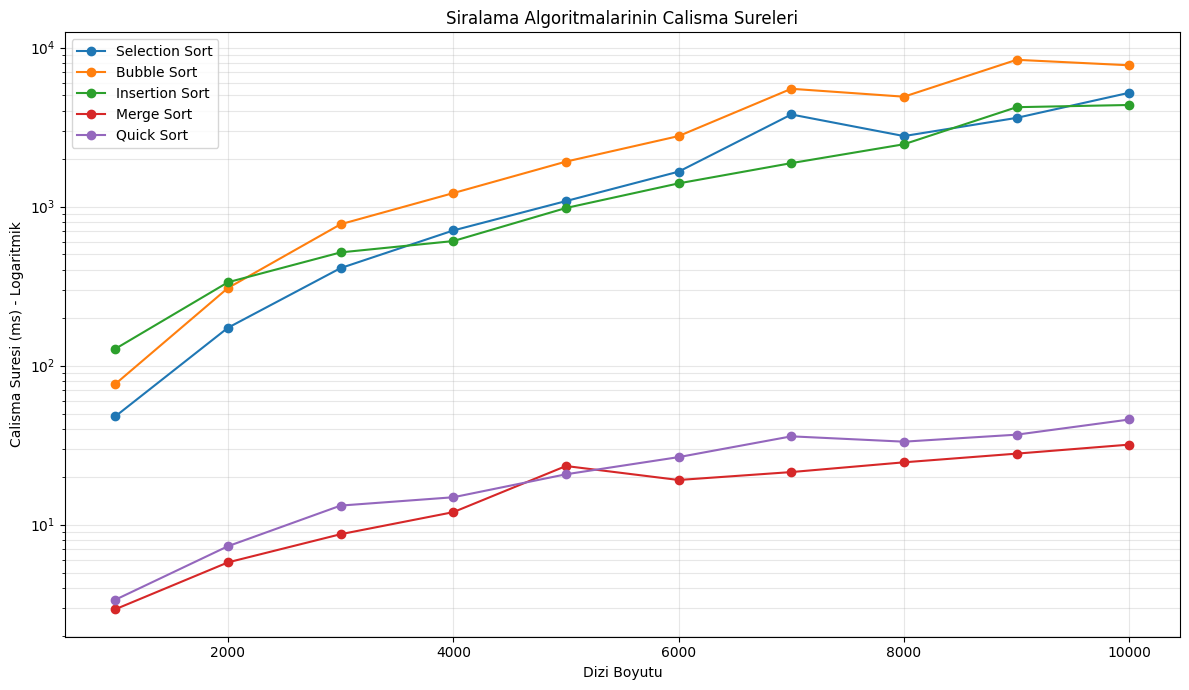

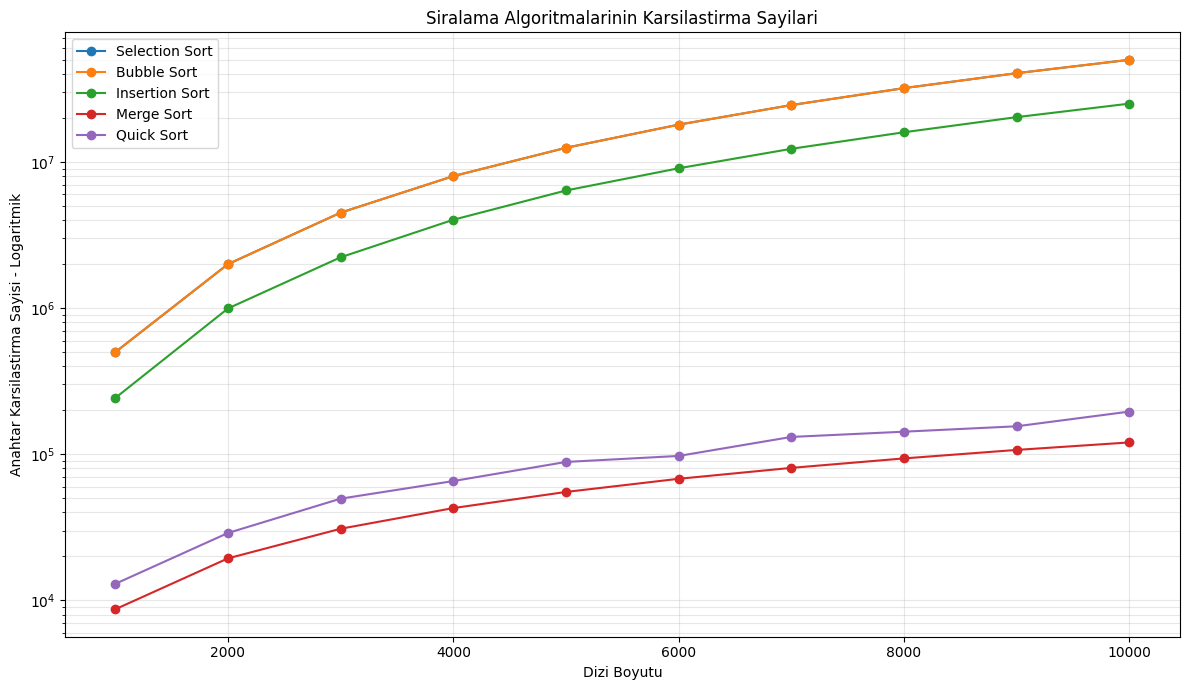

In [43]:

import pandas as pd
import matplotlib.pyplot as plt

# Daha önce oluşturduğumuz sonuç listeleri
sonuclar = {
    "Selection Sort": selection_sonuclari,
    "Bubble Sort": bubble_sonuclari,
    "Insertion Sort": insertion_sonuclari,
    "Merge Sort": merge_sonuclari,
    "Quick Sort": quick_sonuclari
}

# Birinci grafik: Çalışma süreleri
plt.figure(figsize=(12, 7))

for isim, veriler in sonuclar.items():
    boyutlar = [satir[0] for satir in veriler]
    sureler = [satir[1] for satir in veriler]

    plt.plot(
        boyutlar,
        sureler,
        marker="o",
        label=isim
    )

plt.yscale("log")
plt.xlabel("Dizi Boyutu")
plt.ylabel("Calisma Suresi (ms) - Logaritmik")
plt.title("Siralama Algoritmalarinin Calisma Sureleri")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig("Siralama_Sure_Grafigi.png", dpi=300)
plt.show()

# İkinci grafik: Karşılaştırma sayıları
plt.figure(figsize=(12, 7))

for isim, veriler in sonuclar.items():
    boyutlar = [satir[0] for satir in veriler]
    karsilastirmalar = [satir[2] for satir in veriler]

    plt.plot(
        boyutlar,
        karsilastirmalar,
        marker="o",
        label=isim
    )

plt.yscale("log")
plt.xlabel("Dizi Boyutu")
plt.ylabel("Anahtar Karsilastirma Sayisi - Logaritmik")
plt.title("Siralama Algoritmalarinin Karsilastirma Sayilari")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig("Siralama_Karsilastirma_Grafigi.png", dpi=300)
plt.show()


In [44]:

import pandas as pd

# Tüm algoritmaların deney sonuçlarını birleştir
veriler = []

for isim, sonuclar in [
    ("Selection Sort", selection_sonuclari),
    ("Bubble Sort", bubble_sonuclari),
    ("Insertion Sort", insertion_sonuclari),
    ("Merge Sort", merge_sonuclari),
    ("Quick Sort", quick_sonuclari)
]:
    for boyut, sure, karsilastirma in sonuclar:
        veriler.append({
            "Algoritma": isim,
            "Dizi_Boyutu": boyut,
            "Sure_ms": sure,
            "Karsilastirma_Sayisi": karsilastirma
        })

df_siralama = pd.DataFrame(veriler)

# CSV dosyasına kaydet
df_siralama.to_csv(
    "Siralama_Algoritmalari_Sonuclari.csv",
    index=False
)

print(df_siralama.to_string(index=False))
print("\nSonuçlar CSV dosyasına kaydedildi.")


     Algoritma  Dizi_Boyutu     Sure_ms  Karsilastirma_Sayisi
Selection Sort         1000   47.979568                499500
Selection Sort         2000  173.148279               1999000
Selection Sort         3000  410.570227               4498500
Selection Sort         4000  707.730584               7998000
Selection Sort         5000 1082.990293              12497500
Selection Sort         6000 1658.194914              17997000
Selection Sort         7000 3793.511144              24496500
Selection Sort         8000 2774.888422              31996000
Selection Sort         9000 3611.395243              40495500
Selection Sort        10000 5195.249643              49995000
   Bubble Sort         1000   76.657159                499500
   Bubble Sort         2000  307.910073               1999000
   Bubble Sort         3000  774.475304               4498500
   Bubble Sort         4000 1215.577731               7998000
   Bubble Sort         5000 1917.396052              12497500
   Bubbl